In [8]:
import pandas as pd
import numpy as np
import re

DATA_PATH = "get_it_done_closed_16-25.csv"

all_data = pd.read_csv(DATA_PATH, low_memory=False)
all_data = all_data.drop(columns=[c for c in all_data.columns if c.startswith("Unnamed:")])

# Basic cleaning from notebook 4
master = all_data[all_data["status"] != "Referred"].drop(columns=["referred"], errors="ignore")
master["comm_plan_name"] = master["comm_plan_name"].str.title()

def clean_case_type(case):
    if not isinstance(case, str):
        return case
    if "graffiti" in case.lower():
        return "Graffiti"
    return case

master = master[master["service_name"] != "Other"]
master = master[master["case_age_days"] >= 0]
master = master[~master["service_request_id"].duplicated()]
master["service_name"] = master["service_name"].apply(clean_case_type)

# Feature engineering
model_data = master.copy()
model_data = model_data[model_data["case_age_days"] <= 365 * 2]

model_data["date_requested"] = pd.to_datetime(model_data["date_requested"], errors="coerce")
model_data = model_data.dropna(subset=["date_requested"]).sort_values("date_requested").reset_index(drop=True)

model_data["year"] = model_data["date_requested"].dt.year
model_data["month"] = model_data["date_requested"].dt.month
model_data["day_of_week"] = model_data["date_requested"].dt.dayofweek
model_data["hour"] = model_data["date_requested"].dt.hour
model_data["quarter"] = model_data["date_requested"].dt.quarter
model_data["is_weekend"] = (model_data["day_of_week"] >= 5).astype(int)

model_data["council_district"] = model_data["council_district"].fillna(0)
model_data["is_district_56"] = model_data["council_district"].isin([5, 6]).astype(int)
model_data["is_followup"] = model_data["service_request_parent_id"].notna().astype(int)
model_data["description_length"] = model_data["public_description"].str.len().fillna(0)
model_data["has_description"] = (model_data["description_length"] > 0).astype(int)
model_data["log_wait"] = np.log1p(model_data["case_age_days"])

# Clean service_name_detail
def norm_text(x):
    x = str(x).strip().lower()
    return re.sub(r"\s+", " ", x)

s_raw = model_data["service_name"].fillna("Missing").astype(str)
d_raw = model_data["service_name_detail"].fillna("Missing").astype(str)

s_norm = s_raw.map(norm_text)
d_norm = d_raw.map(norm_text)
same_mask = d_norm == s_norm

model_data["service_name_detail_clean"] = np.where(
    same_mask,
    "SameAsService",
    d_raw
).astype(str)

counts = model_data["service_name_detail_clean"].value_counts()
rare = counts[counts < 150].index
model_data["service_name_detail_clean"] = model_data["service_name_detail_clean"].replace(rare, "Other")
model_data["has_extra_detail"] = (~same_mask).astype(int)

# Workload features
model_data["service_name"] = model_data["service_name"].fillna("Missing").astype(str)
model_data["comm_plan_name"] = model_data["comm_plan_name"].fillna("Missing").astype(str)
model_data["_one"] = 1.0

model_data["workload_30d_service"] = (
    model_data.groupby("service_name", group_keys=False)
    .apply(lambda g: pd.Series(
        g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
        index=g.index
    ))
    .fillna(0)
)

model_data["workload_30d_neighborhood"] = (
    model_data.groupby("comm_plan_name", group_keys=False)
    .apply(lambda g: pd.Series(
        g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
        index=g.index
    ))
    .fillna(0)
)

model_data["workload_30d_service_neighborhood"] = (
    model_data.groupby(["service_name", "comm_plan_name"], group_keys=False)
    .apply(lambda g: pd.Series(
        g.set_index("date_requested")["_one"].rolling("30D", closed="left").sum().to_numpy(),
        index=g.index
    ))
    .fillna(0)
)

model_data["service_x_neighborhood"] = (
    model_data["service_name"] + " | " + model_data["comm_plan_name"]
)

vc = model_data["service_x_neighborhood"].value_counts()
rare = vc[vc < 100].index
model_data["service_x_neighborhood"] = model_data["service_x_neighborhood"].replace(rare, "Other")

model_data = model_data.drop(columns=["_one"])

# This is the year_df from notebook 4
cat_df = model_data[model_data["year"] >= 2023].copy()

year_df = cat_df.copy()
year_df = year_df[
    (year_df["date_requested"] < "2025-01-01") &
    (year_df["case_age_days"] <= 365)
].sort_values("date_requested").copy()

print(year_df.shape)
year_df.head()

/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_33313/928972428.py:77: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_33313/928972428.py:86: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(
/var/folders/xg/pjqjkzbx1lz9fgmz_njxvl6w0000gn/T/ipykernel_33313/928972428.py:95: FutureWarning: DataFrameGr

(753888, 41)


,service_request_id,service_request_parent_id,sap_notification_number,date_requested,case_age_days,case_record_type,service_name,service_name_detail,date_closed,status,...,is_followup,description_length,has_description,log_wait,service_name_detail_clean,has_extra_detail,workload_30d_service,workload_30d_neighborhood,workload_30d_service_neighborhood,service_x_neighborhood
1367439,4044811,4036490.0,NaN,2023-01-01 00:35:00,9.0,Traffic Engineering,Traffic Signal Timing,NaN,2023-01-10,Closed,...,1,14.0,1,2.302585,Missing,1,260.0,429.0,10.0,Traffic Signal Timing | Linda Vista
1367440,4044817,NaN,NaN,2023-01-01 02:31:00,1.0,Neighborhood Policing,Encampment,NaN,2023-01-02,Closed,...,0,35.0,1,0.693147,Missing,1,4152.0,1412.0,304.0,Encampment | Uptown
1367441,4044818,NaN,40300650399.0,2023-01-01 02:41:00,2.0,TSW,Street Light Maintenance,POLE KNOCK OVER/DAMAGE,2023-01-03,Closed,...,0,46.0,1,1.098612,POLE KNOCK OVER/DAMAGE,1,797.0,366.0,20.0,Street Light Maintenance | Rancho Penasquitos
1367442,4044819,NaN,40300650466.0,2023-01-01 02:43:00,1.0,TSW,Traffic Signal Issue,SIGNAL FACING WRONG DIRECTION,2023-01-02,Closed,...,0,71.0,1,0.693147,SIGNAL FACING WRONG DIRECTION,1,499.0,990.0,7.0,Traffic Signal Issue | Encanto Neighborhoods
1367443,4044820,NaN,40300650510.0,2023-01-01 03:01:00,15.0,TSW,Street Flooded,NaN,2023-01-16,Closed,...,0,8.0,1,2.772589,Missing,1,120.0,375.0,2.0,Street Flooded | Mission Valley


time_response_thresh
same_day          0.267195
next_1_3_days     0.237009
within_1_week     0.155002
within_1_month    0.198955
within_1_year     0.141839
Name: proportion, dtype: float64

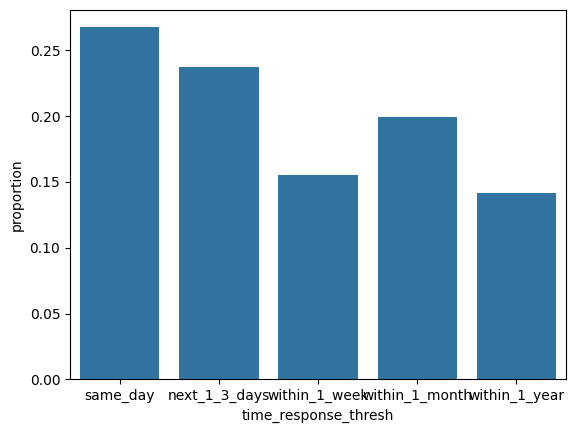

In [35]:
case_thresholds = [-0.1, 0, 3, 7, 30, 365]
import seaborn as sns
case_labels = [
    "same_day",
    "next_1_3_days",
    "within_1_week",
   
    "within_1_month",
    
    "within_1_year"
]

year_df['time_response_thresh'] = pd.cut(year_df['case_age_days'], case_thresholds, labels =case_labels)
sns.barplot(year_df['time_response_thresh'].value_counts(normalize = True))
year_df["time_response_thresh"].value_counts(normalize = True).sort_index()

In [36]:
x_numerical = ['year', 'month', 'description_length', 'hour', 'is_followup','day_of_week', "workload_30d_service", "workload_30d_neighborhood", "workload_30d_service_neighborhood"]
x_cat = ['service_name', 'council_district', 'comm_plan_name', 'case_origin', 'case_record_type', 'service_x_neighborhood']
for c in x_cat:
    year_df[c] = year_df[c].fillna("Missing").astype(str)
x_numerical.sort()
x_cat.sort()
y = 'time_response_thresh'
x_total = x_numerical + x_cat
shape = len(year_df)
train_df = year_df[:int(shape*0.7)].copy()
valid_df = year_df[int(shape*.7):int(shape*.85)].copy()
test_df = year_df[int(shape*.85):].copy()

print(f'train_df shape is {train_df.shape} | {len(train_df)/len(year_df)*100}%')
print(f'valid_df shape is {valid_df.shape} | {len(valid_df)/len(year_df)*100}%')
print(f'test_df shape is {test_df.shape} | {len(test_df)/len(year_df)*100}%')


X_train = train_df[x_total]
X_valid = valid_df[x_total]
X_test = test_df[x_total]

y_train = train_df[y]
y_valid = valid_df[y]
y_test = test_df[y]

train_df shape is (527721, 42) | 69.99992041258119%
valid_df shape is (113083, 42) | 14.999973470860391%
test_df shape is (113084, 42) | 15.00010611655843%


In [37]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
cat_boost = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1",
    auto_class_weights = "Balanced",
    iterations=300,

    learning_rate=0.08,
    depth=5,
    random_seed = 42,
    od_type = 'Iter',
    od_wait = 30,
    verbose = 50,

)
cat_boost.fit(X_train, y_train, cat_features = x_cat, eval_set=(X_valid, y_valid),
    use_best_model=True)
pred=cat_boost.predict(X_test).flatten()

print("Accuracy:", accuracy_score(y_test, pred))
print("Macro F1:", f1_score(y_test, pred, average="macro"))
print("Weighted F1:", f1_score(y_test, pred, average="weighted"))
print()
print(classification_report(y_test, pred))


0:	learn: 0.4847954	test: 0.4822212	best: 0.4822212 (0)	total: 397ms	remaining: 1m 58s
100:	learn: 0.5504311	test: 0.5412818	best: 0.5412818 (100)	total: 34.4s	remaining: 1m 7s
200:	learn: 0.5637478	test: 0.5477903	best: 0.5477903 (200)	total: 1m 14s	remaining: 36.8s
299:	learn: 0.5705829	test: 0.5475662	best: 0.5483492 (255)	total: 1m 57s	remaining: 0us

bestTest = 0.5483492176
bestIteration = 255

Shrink model to first 256 iterations.
Accuracy: 0.5332407767677125
Macro F1: 0.5009303989901237
Weighted F1: 0.5450282364754564

                precision    recall  f1-score   support

 next_1_3_days       0.57      0.51      0.54     29887
      same_day       0.94      0.70      0.80     32776
within_1_month       0.38      0.30      0.33     19924
 within_1_week       0.31      0.38      0.34     15990
 within_1_year       0.38      0.69      0.49     14507

      accuracy                           0.53    113084
     macro avg       0.52      0.52      0.50    113084
  weighted avg    

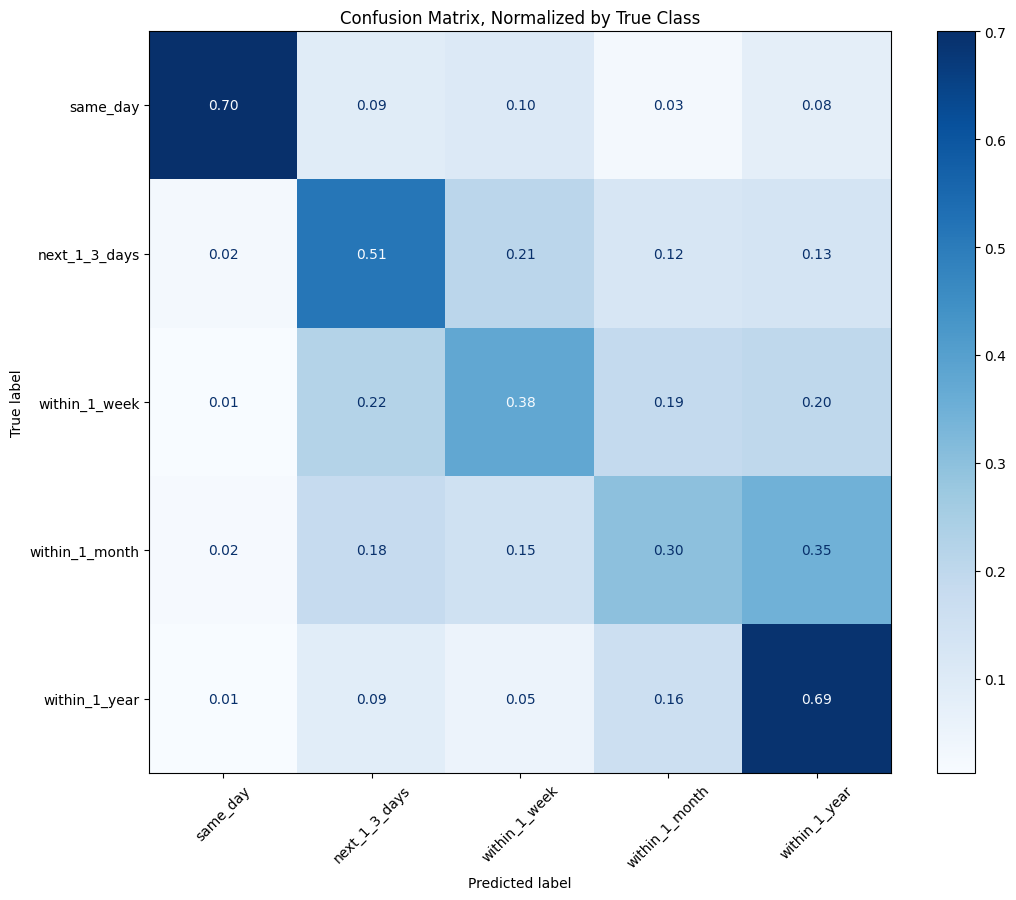

In [38]:
cm_norm = confusion_matrix(
    y_test.astype(str),
    pred,
    labels=case_labels,
    normalize="true"
)
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=case_labels)
fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format=".2f")
plt.title("Confusion Matrix, Normalized by True Class")
plt.tight_layout()
plt.show()